# Adding Sunglasses for a Cool New Look
**Name :** KAYUM AASIF S    **Reg. No :** 212225230136

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

#### 1. Load the face image

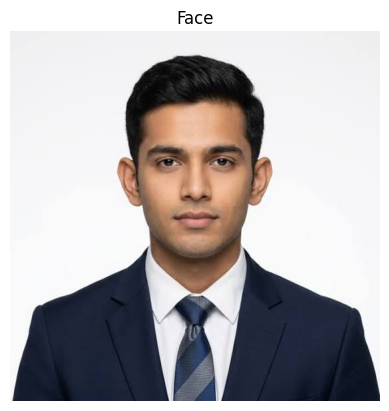

(554, 554, 3)


In [2]:
faceImage = cv2.imread('pass_1.jpeg')
plt.imshow(faceImage[:, :, ::-1]); plt.title("Face"); plt.axis('off')
plt.show()
print(faceImage.shape)

#### 2. Load the sunglass image
The sunglass is a JPEG (no alpha channel) with a white background, so we crop the stray grey line at the bottom and build our own mask.

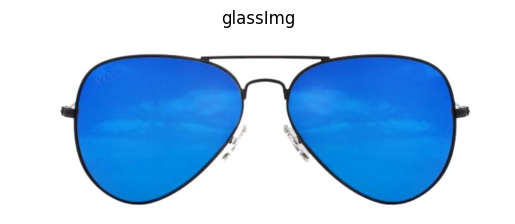

(335, 912, 3)


In [3]:
glassImg = cv2.imread('glasss_1.jpeg')[:335]      # drop grey line at the bottom edge
plt.imshow(glassImg[:, :, ::-1]); plt.title("glassImg"); plt.axis('off')
plt.show()
print(glassImg.shape)

#### 3. Create the alpha mask (non-white pixels = sunglass) and crop to its bounding box

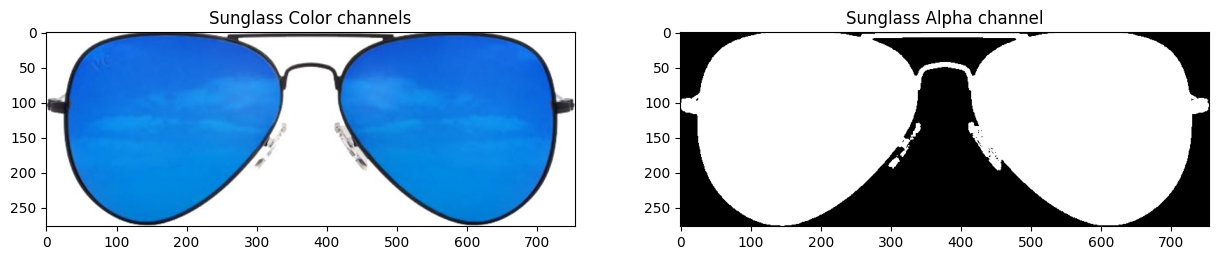

In [4]:
gray = cv2.cvtColor(glassImg, cv2.COLOR_BGR2GRAY)
_, glassMask1 = cv2.threshold(gray, 235, 255, cv2.THRESH_BINARY_INV)

x, y, w, h = cv2.boundingRect(glassMask1)
glassBGR   = glassImg[y:y+h, x:x+w]
glassMask1 = glassMask1[y:y+h, x:x+w]

plt.figure(figsize=[15, 15])
plt.subplot(121); plt.imshow(glassBGR[:, :, ::-1]); plt.title('Sunglass Color channels')
plt.subplot(122); plt.imshow(glassMask1, cmap='gray'); plt.title('Sunglass Alpha channel')
plt.show()

#### 4. Resize the sunglass to fit over the eye region

In [5]:
newW = 215
newH = int(h * newW / w)
glassBGR   = cv2.resize(glassBGR,   (newW, newH), interpolation=cv2.INTER_AREA)
glassMask1 = cv2.resize(glassMask1, (newW, newH), interpolation=cv2.INTER_AREA)
print("Sunglass dimension =", glassBGR.shape)

# Eye region (centre of the glasses placed at x=277, y=200)
x0 = 277 - newW // 2
y0 = 200 - newH // 2
x1, y1 = x0 + newW, y0 + newH

Sunglass dimension = (78, 215, 3)


#### 5. Naive replacement (the white background of the glasses is visible)

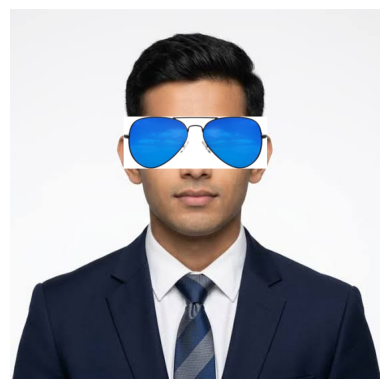

In [6]:
faceWithGlassesNaive = faceImage.copy()
faceWithGlassesNaive[y0:y1, x0:x1] = glassBGR
plt.imshow(faceWithGlassesNaive[..., ::-1]); plt.axis('off')
plt.show()

#### 6. Using the mask with arithmetic operations

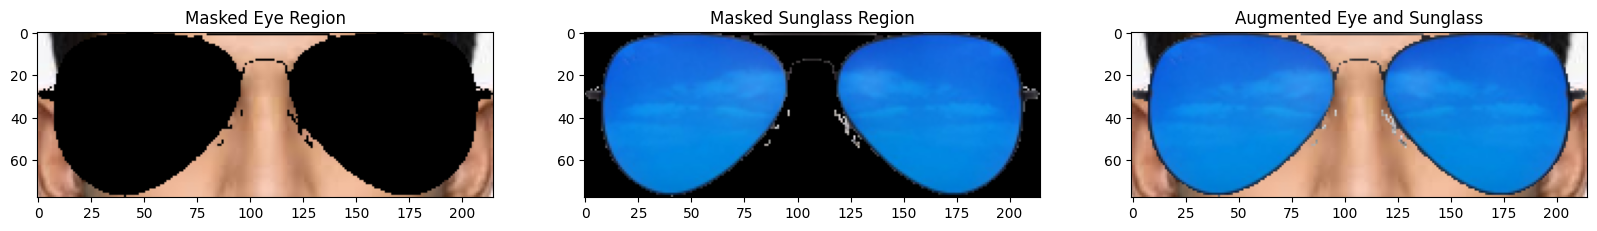

In [7]:
# 3-channel mask with values in [0,1]
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))
glassMask = np.uint8(glassMask / 255)

faceWithGlassesArithmetic = faceImage.copy()
eyeROI = faceWithGlassesArithmetic[y0:y1, x0:x1]

maskedEye   = cv2.multiply(eyeROI,   1 - glassMask)
maskedGlass = cv2.multiply(glassBGR, glassMask)
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

plt.figure(figsize=[20, 20])
plt.subplot(131); plt.imshow(maskedEye[..., ::-1]);   plt.title("Masked Eye Region")
plt.subplot(132); plt.imshow(maskedGlass[..., ::-1]); plt.title("Masked Sunglass Region")
plt.subplot(133); plt.imshow(eyeRoiFinal[..., ::-1]); plt.title("Augmented Eye and Sunglass")
plt.show()

#### 7. Final result

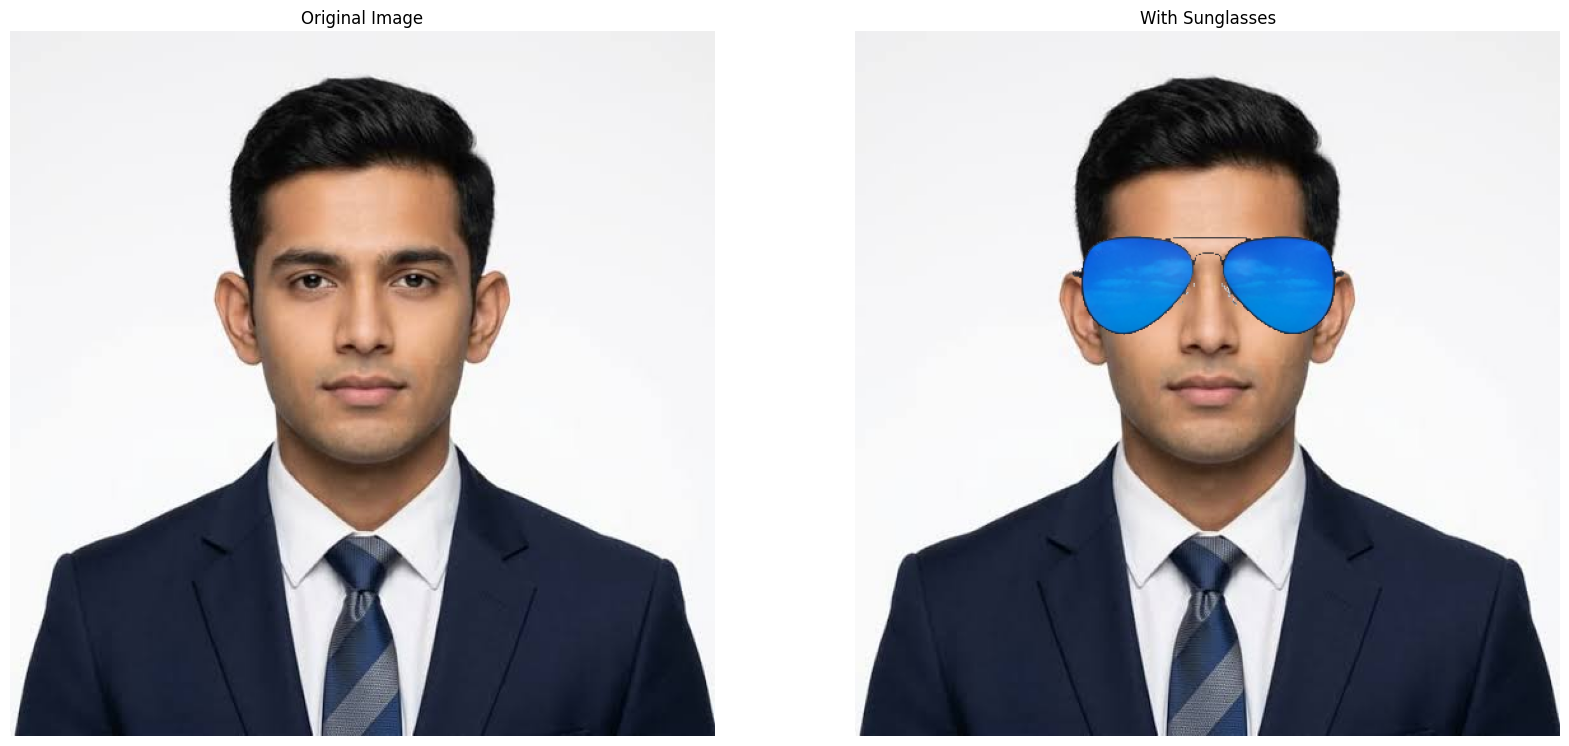

In [8]:
faceWithGlassesArithmetic[y0:y1, x0:x1] = eyeRoiFinal

plt.figure(figsize=[20, 20])
plt.subplot(121); plt.imshow(faceImage[:, :, ::-1]); plt.title("Original Image"); plt.axis('off')
plt.subplot(122); plt.imshow(faceWithGlassesArithmetic[:, :, ::-1]); plt.title("With Sunglasses"); plt.axis('off')
plt.show()